#Conectando

In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
import pandas as pd

In [ ]:
dados = pd.read_excel('/content/drive/MyDrive/Curso Análise de Dados - Eu ProgrAmo/Módulo 7/analise_dados_mod7.xlsx')

#Feature Engineering

In [ ]:
dados.columns

Index(['ID', 'IDADE', 'FAIXA IDADE', 'GENERO', 'COR/RACA/ETNIA', 'PCD',
       'EXPERIENCIA_PROFISSIONAL_PREJUDICADA', 'ASPECTOS_PREJUDICADOS',
       'VIVE_NO_BRASIL', 'ESTADO ONDE MORA', 'UF ONDE MORA',
       'REGIAO ONDE MORA', 'MUDOU DE ESTADO?', 'REGIAO DE ORIGEM',
       'NIVEL DE ENSINO', 'ÁREA DE FORMAÇÃO',
       'QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?', 'SETOR',
       'NUMERO DE FUNCIONARIOS', 'GESTOR?', 'CARGO COMO GESTOR', 'CARGO ATUAL',
       'FAIXA SALARIAL',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE TI/ENGENHARIA DE SOFTWARE VOCÊ TEVE ANTES DE COMEÇAR A TRABALHAR NA ÁREA DE DADOS?',
       'SALARIO', 'NOVO_NIVEL', 'NIVEL_Júnior', 'NIVEL_Pleno', 'NIVEL_Sênior',
       'GEARACAO', 'Quanto tempo de experiência na área de dados você tem?',
       'Quanto tempo de experiência na área de TI/Engenharia de Software você teve antes de começar a trabalhar na área de dados?',
       'Você está satisfeito na sua 

In [ ]:
dados['QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?'].value_counts()

,count
QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?,
Empregado (CLT),2762
Empreendedor ou Empregado (CNPJ),410
"Desempregado, buscando recolocação",350
Estagiário,188
Servidor Público,156
Trabalho na área Acadêmica/Pesquisador,86
Somente Estudante (graduação),82
Vivo no Brasil e trabalho remoto para empresa de fora do Brasil,69
Vivo fora do Brasil e trabalho para empresa de fora do Brasil,46


In [ ]:
dados = dados[dados['QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?'] == 'Empregado (CLT)'] #vamos analisar somente CLT

In [ ]:
dados['QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?'].value_counts()

,count
QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?,
Empregado (CLT),2762


In [ ]:
dados['COR/RACA/ETNIA'].value_counts()

,count
COR/RACA/ETNIA,
Branca,1805
Parda,661
Preta,181
Amarela,85
Prefiro não informar,16
Outra,10
Indígena,4


In [ ]:
lista_retirar = ['Prefro não informar', 'Outra', 'Indígena'] #retira os q tem poucas pessoas para não dar problemas na proporção

In [ ]:
dados = dados[~dados['COR/RACA/ETNIA'].isin(lista_retirar)] #o ~ faz o contrário, então com a func isin (adicionar) ele acaba retirando

In [ ]:
dados['NAO BRANCA'] = dados['COR/RACA/ETNIA'].apply(lambda x: 1 if x != 'Branca' else 0) #se cor for diferente de branca, conta 1, se não, 0

In [ ]:
dados['COR/RACA/ETNIA'].value_counts()

,count
COR/RACA/ETNIA,
Branca,1805
Parda,661
Preta,181
Amarela,85
Prefiro não informar,16


In [ ]:
dados['QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?'].value_counts()

,count
QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?,
de 1 a 2 anos,750
de 3 a 4 anos,584
de 4 a 6 anos,420
Menos de 1 ano,356
Mais de 10 anos,277
de 7 a 10 anos,234
Não tenho experiência na área de dados,127


In [ ]:
dados['TEMPO EXPERIENCIA'] = dados['QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?'].str.extract(r'(\d+)')
#r = radical da string  d = pega só primeiro dígito q aparecer  + = pega próximos digitos se não houver interferência ('1 2' não pega, '12' pega)

In [ ]:
dados['TEMPO EXPERIENCIA'].value_counts()

,count
TEMPO EXPERIENCIA,
1,1106
3,584
4,420
10,277
7,234


In [ ]:
#faltou o "não tenho experiência", então:
dados['TEMPO EXPERIENCIA'] = dados['TEMPO EXPERIENCIA'].fillna(0)

In [ ]:
dados['TEMPO EXPERIENCIA'].value_counts() #menos de 1 ano de experiência vira 0

,count
TEMPO EXPERIENCIA,
1,1106
3,584
4,420
10,277
7,234
0,127


In [ ]:
dados['NUMERO DE FUNCIONARIOS'].value_counts()

,count
NUMERO DE FUNCIONARIOS,
Acima de 3.000,1319
de 101 a 500,506
de 1.001 a 3.000,371
de 501 a 1.000,248
de 51 a 100,148
de 11 a 50,114
de 6 a 10,24
de 1 a 5,18


In [ ]:
dados['NUMERO DE FUNCIONARIOS'] = dados['NUMERO DE FUNCIONARIOS'].str.replace('.', '') #substitui o . do número (1.000) por nada (1000)

In [ ]:
dados['NUMERO DE FUNCIONARIOS'] = dados['NUMERO DE FUNCIONARIOS'].str.extract(r'(\d+)')

In [ ]:
dados['NUMERO DE FUNCIONARIOS'].value_counts()

,count
NUMERO DE FUNCIONARIOS,
3000,1319
101,506
1001,371
501,248
51,148
11,114
6,24
1,18


In [ ]:
dados['Qual o principal motivo da sua insatisfação com a empresa atual?'].value_counts()

,count
Qual o principal motivo da sua insatisfação com a empresa atual?,
Gostaria de trabalhar em em outra área de atuação,69
Salário atual não corresponde ao mercado,53
Falta de oportunidade de crescimento no emprego atual,46
Falta de maturidade analítica na empresa,45
"Falta de oportunidade de crescimento no emprego atual, Salário atual não corresponde ao mercado, Falta de maturidade analítica na empresa",26
...,...
"O clima de trabalho/ambiente não é bom, Não tenho uma boa relação com meu líder/gestor, Gostaria de receber mais benefícios",1
Falta de organização nos processos internos,1
"Gostaria de receber mais benefícios, O clima de trabalho/ambiente não é bom, Falta de oportunidade de crescimento no emprego atual",1


In [ ]:
dados['INSATISFACAO'] = 0 #vamos analisar a insatisfação com o salário

In [ ]:
dados.loc[dados['Qual o principal motivo da sua insatisfação com a empresa atual?'].notnull(),
          'Qual o principal motivo da sua insatisfação com a empresa atual?'].apply(lambda x: 1 if 'Salário' in x else 0)
          #conta 1 se tiver a palavra 'Salário' na razão de insatisfação

,Qual o principal motivo da sua insatisfação com a empresa atual?
1,0
2,0
7,1
10,0
26,1
...,...
4227,0
4234,1
4238,0
4240,1


In [ ]:
dados.loc[dados['Qual o principal motivo da sua insatisfação com a empresa atual?'].notnull(), 'INSATISFACAO'] = dados.loc[dados['Qual o principal motivo da sua insatisfação com a empresa atual?'].notnull(),
          'Qual o principal motivo da sua insatisfação com a empresa atual?'].apply(lambda x: 1 if 'Salário' in x else 0) #atribui tudo a coluna insatisfação

In [ ]:
dados['INSATISFACAO'].value_counts() #282 insatisfeitos com o salário

,count
INSATISFACAO,
0,2466
1,282


In [ ]:
dados['NIVEL DE ENSINO'].value_counts()

,count
NIVEL DE ENSINO,
Graduação/Bacharelado,1034
Pós-graduação,980
Mestrado,306
Estudante de Graduação,272
Doutorado ou Phd,100
Não tenho graduação formal,52
Prefiro não informar,4


In [ ]:
dados['NIVEL DE ENSINO'] = dados['NIVEL DE ENSINO'].apply(lambda x: 0 if x == 'Não tenho graduação formal' else
                                                          1 if x == 'Estudante de Graduação' else
                                                          2 if x == 'Graduação/Bacharelado' else
                                                          3 if x == 'Pós-graduação' else
                                                          4 if x == 'Mestrado' else
                                                          5 if x == 'Doutorado ou Phd' else -1)

In [ ]:
dados['NIVEL DE ENSINO'].value_counts()

,count
NIVEL DE ENSINO,
2,1034
3,980
4,306
1,272
5,100
0,52
-1,4


##Preparando para os testes de regressão linear


In [ ]:
dados.columns

Index(['ID', 'IDADE', 'FAIXA IDADE', 'GENERO', 'COR/RACA/ETNIA', 'PCD',
       'EXPERIENCIA_PROFISSIONAL_PREJUDICADA', 'ASPECTOS_PREJUDICADOS',
       'VIVE_NO_BRASIL', 'ESTADO ONDE MORA', 'UF ONDE MORA',
       'REGIAO ONDE MORA', 'MUDOU DE ESTADO?', 'REGIAO DE ORIGEM',
       'NIVEL DE ENSINO', 'ÁREA DE FORMAÇÃO',
       'QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?', 'SETOR',
       'NUMERO DE FUNCIONARIOS', 'GESTOR?', 'CARGO COMO GESTOR', 'CARGO ATUAL',
       'FAIXA SALARIAL',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE TI/ENGENHARIA DE SOFTWARE VOCÊ TEVE ANTES DE COMEÇAR A TRABALHAR NA ÁREA DE DADOS?',
       'SALARIO', 'NOVO_NIVEL', 'NIVEL_Júnior', 'NIVEL_Pleno', 'NIVEL_Sênior',
       'GEARACAO', 'Quanto tempo de experiência na área de dados você tem?',
       'Quanto tempo de experiência na área de TI/Engenharia de Software você teve antes de começar a trabalhar na área de dados?',
       'Você está satisfeito na sua 

In [ ]:
dados = dados[['IDADE', 'GENERO', 'NAO BRANCA', 'REGIAO ONDE MORA', 'NIVEL DE ENSINO', 'NOVO_NIVEL', 'SETOR', 'NUMERO DE FUNCIONARIOS',
              'TEMPO EXPERIENCIA', 'INSATISFACAO', 'SALARIO']]

In [ ]:
dados.columns

Index(['IDADE', 'GENERO', 'NAO BRANCA', 'REGIAO ONDE MORA', 'NIVEL DE ENSINO',
       'NOVO_NIVEL', 'SETOR', 'NUMERO DE FUNCIONARIOS', 'TEMPO EXPERIENCIA',
       'INSATISFACAO', 'SALARIO'],
      dtype='object')

In [ ]:
dados = pd.get_dummies(dados, columns = ['GENERO', 'SETOR', 'NOVO_NIVEL', 'REGIAO ONDE MORA'], drop_first = True)
#usa o get_dummier já q são colunas q não podem ser contadas por números ou em ordem crescente

In [ ]:
dados

,IDADE,NAO BRANCA,NIVEL DE ENSINO,NUMERO DE FUNCIONARIOS,TEMPO EXPERIENCIA,INSATISFACAO,SALARIO,GENERO_Masculino,GENERO_Prefiro não informar,SETOR_Educação,...,SETOR_Varejo,SETOR_Área da Saúde,SETOR_Área de Consultoria,NOVO_NIVEL_Pessoa Gestora,NOVO_NIVEL_Pleno,NOVO_NIVEL_Sênior,REGIAO ONDE MORA_Nordeste,REGIAO ONDE MORA_Norte,REGIAO ONDE MORA_Sudeste,REGIAO ONDE MORA_Sul
1,32.0,1,2,3000,3,0,4695.0,True,False,False,...,False,False,False,True,False,False,False,True,False,False
2,53.0,0,3,3000,3,0,14202.0,True,False,False,...,False,False,False,False,True,False,False,False,False,False
3,27.0,0,5,3000,4,0,15463.0,True,False,False,...,False,False,False,False,False,True,False,False,True,False
6,21.0,1,1,3000,1,0,4491.0,True,False,False,...,False,False,False,False,False,False,False,False,True,False
7,31.0,0,2,6,1,1,2704.0,False,False,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4262,31.0,1,3,501,3,0,18402.0,True,False,False,...,False,False,False,True,False,False,False,False,True,False
4263,26.0,1,2,501,3,0,6641.0,True,False,False,...,False,False,False,False,False,False,False,False,True,False
4266,26.0,0,2,3000,3,0,4329.0,True,False,False,...,False,False,False,False,True,False,False,False,True,False
4267,30.0,0,4,51,1,0,3758.0,False,False,False,...,False,False,True,False,True,False,False,False,True,False


In [ ]:
X = dados.drop('SALARIO', axis=1) #atributos (e axis=1 para tirar a coluna toda)
y = dados['SALARIO'] #target, objetivo

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
#20% dos dados será para teste e 80% treino, e random_state para reproduzir uma divisão específica (42), já q são aleatórias

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler() #objeto de normalização

X_train_scaled = scaler.fit_transform(X_train) #treino
X_test_scaled = scaler.fit_transform(X_test) #teste

##Treinando o Modelo

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model = LinearRegression()

In [ ]:
model.fit(X_train_scaled, y_train) #tenta aprender analisando a relação entre  variáveis de entrada (X_train_scaled) e os valores corretos esperados (y_train)
#por exemplo, relacionar a relação do nível, escolaridade, região e prever o salário (y)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_scaled) #predições do conjunto de teste
y_pred

array([ 1.69947318e+04,  7.30642716e+03,  1.18529657e+04,  2.82758191e+03,
        9.83164668e+03,  1.15651363e+04,  1.28857298e+04,  1.18497287e+04,
        1.81047132e+04,  1.22730150e+04,  3.65143388e+03,  8.36237457e+03,
        8.03690833e+03,  1.36237472e+04,  2.39802457e+04,  1.16640949e+04,
        1.15651363e+04,  9.59382663e+03,  5.98712288e+03,  4.96793165e+03,
        9.44609463e+03,  7.66046193e+03,  8.34802773e+03,  9.06460232e+03,
       -6.45872578e+02,  7.11442541e+03,  1.60593401e+04,  3.28465619e+03,
        2.12555574e+04,  1.88731417e+04,  1.83462266e+04,  2.29368399e+04,
        1.87386728e+04,  2.35402843e+04,  8.64512104e+03,  1.68486181e+04,
        7.30769452e+03,  5.49831207e+03,  1.27113525e+04,  1.16648474e+03,
        1.09896144e+04,  6.69264898e+03,  1.09491753e+04,  2.16417239e+03,
        2.22982833e+04,  1.65061092e+04,  2.43957601e+04,  1.99529574e+04,
        1.00045617e+04,  1.54161961e+04,  6.19924793e+03,  4.89385594e+03,
        1.04169456e+04,  

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
mse = mean_squared_error(y_test, y_pred) #erro quadrático médio: pega o erro, eleva ao quadrado e faz a média, penalizando erros
mse #valor muito alto = muitos erros

24130886.665337052

In [ ]:
mae = mean_absolute_error(y_test, y_pred) #erro absoluto médio: média do quanto o modelo erra
mae #erra cerca de R$3275,80 por previsão de salário = previsão ruim

3275.8000626524235

In [ ]:
r2 = r2_score(y_test, y_pred) #coeficiente de determinação: mede quanto do comportamento dos dados o modelo consegue explicar
#1 = perfeito, 0 = não explica nada, negativo: pior que chutar média
r2 #explica 52% da variação dos dados

0.5223781954315845

In [ ]:
#analisando as 3 métricas concluímos que para um modelo real de produção nosso modelo não seria aceitável pois erra muito

##Comparando Valores Reais e Valores Preditos Pelo Modelo

In [ ]:
import matplotlib.pyplot as plt

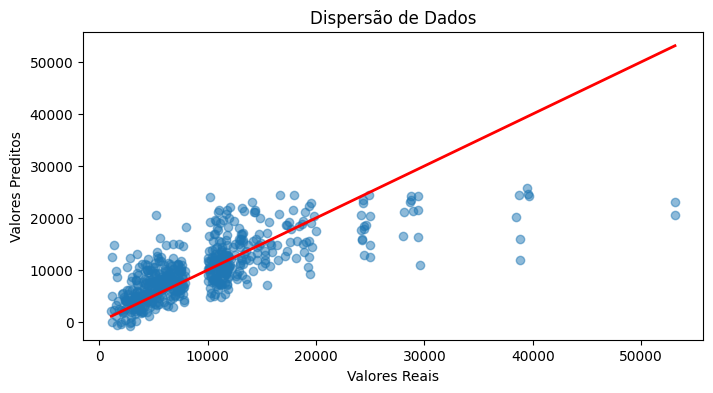

In [ ]:
plt.figure(figsize=(8,4))
plt.scatter(y_test, y_pred, alpha = 0.5) #alpha = transparência dos pontos no gráfico
plt.xlabel('Valores Reais')
plt.ylabel('Valores Preditos')
plt.title('Dispersão de Dados')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color = 'red', linewidth = 2) #pontos de início e fim da linha
plt.show()

In [ ]:
#percebemos que o modelo não prevê bem salários altos

In [ ]:
nomes_atributos = X_train.columns
nomes_atributos

Index(['IDADE', 'NAO BRANCA', 'NIVEL DE ENSINO', 'NUMERO DE FUNCIONARIOS',
       'TEMPO EXPERIENCIA', 'INSATISFACAO', 'GENERO_Masculino',
       'GENERO_Prefiro não informar', 'SETOR_Educação',
       'SETOR_Entretenimento ou Esportes', 'SETOR_Filantropia/ONG's',
       'SETOR_Finanças ou Bancos', 'SETOR_Indústria',
       'SETOR_Internet/Ecommerce', 'SETOR_Marketing', 'SETOR_Outra Opção',
       'SETOR_Seguros ou Previdência', 'SETOR_Setor Alimentício',
       'SETOR_Setor Automotivo', 'SETOR_Setor Farmaceutico',
       'SETOR_Setor Imobiliário/ Construção Civil', 'SETOR_Setor Público',
       'SETOR_Setor de Energia', 'SETOR_Tecnologia/Fábrica de Software',
       'SETOR_Telecomunicação', 'SETOR_Varejo', 'SETOR_Área da Saúde',
       'SETOR_Área de Consultoria', 'NOVO_NIVEL_Pessoa Gestora',
       'NOVO_NIVEL_Pleno', 'NOVO_NIVEL_Sênior', 'REGIAO ONDE MORA_Nordeste',
       'REGIAO ONDE MORA_Norte', 'REGIAO ONDE MORA_Sudeste',
       'REGIAO ONDE MORA_Sul'],
      dtype='object')

In [ ]:
coefs = pd.DataFrame(model.coef_, columns = ['coeficientes'], index = nomes_atributos)
#cria dataframe, add os coeficientes no modelo, indica o nome da coluna de coeficientes e nome do index/linhas
coefs


,coeficientes
IDADE,-81.808793
NAO BRANCA,-308.496086
NIVEL DE ENSINO,919.649038
NUMERO DE FUNCIONARIOS,818.988149
TEMPO EXPERIENCIA,1927.982905
INSATISFACAO,-584.786087
GENERO_Masculino,573.309022
GENERO_Prefiro não informar,140.635037
SETOR_Educação,-291.103123
SETOR_Entretenimento ou Esportes,257.636567


In [ ]:
coefs = coefs.sort_values(by = 'coeficientes', ascending = False) #ordena coluna de coeficientes
coefs

,coeficientes
NOVO_NIVEL_Pessoa Gestora,3990.920966
TEMPO EXPERIENCIA,1927.982905
NOVO_NIVEL_Sênior,1926.201364
NOVO_NIVEL_Pleno,953.750706
NIVEL DE ENSINO,919.649038
NUMERO DE FUNCIONARIOS,818.988149
SETOR_Internet/Ecommerce,631.215287
GENERO_Masculino,573.309022
SETOR_Finanças ou Bancos,521.307717
SETOR_Tecnologia/Fábrica de Software,391.347846


Text(0.5, 1.0, 'Influência das Variáveis no Salário Previsto')

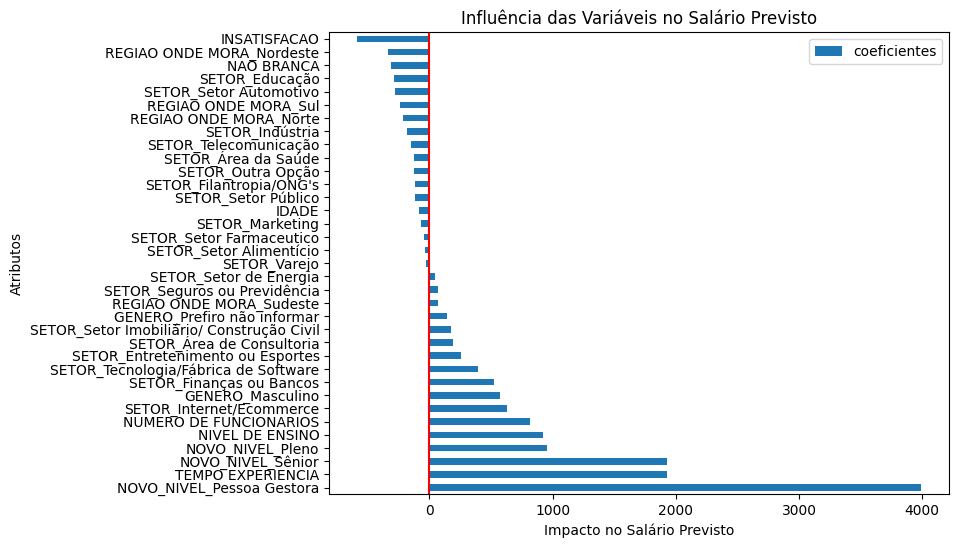

In [74]:
coefs.plot.barh(figsize=(8, 6))
plt.axvline(x=0, color='red') #linha
plt.xlabel('Impacto no Salário Previsto')
plt.ylabel('Atributos')
plt.title('Influência das Variáveis no Salário Previsto')

In [ ]:
#Análise: os coeficientes influenciam no salário, os abaixo de 0 influenciam em um salário baixo, e os acima, em salário alto